# 01. Population marks on the generated nodes

**Question.** The SP mixture places nodes without any attribute. Can we give each node a
population so that (i) the rank-size (Zipf) law of the data is reproduced and (ii) large
populations are clustered together, as in the data?

**Data.** Belgian cities (N = 815, real populations).
**Output.** `out/01_metadata_generative_summary.csv`.
**Paper.** Not in the current version.
**Code.** `src/metadata_marks.py`, `src/synthesis_utils.py`.

**Method.** The population of a node is derived from the local density of nodes around
it, so that it can be applied to the whole mixture (fractal and background).

1. Generate a calibrated SP mixture.
2. Compute the local density of each node (two estimators).
3. Turn the density into a population: (a) power law ρ^β with β fitted on the Zipf
   exponent, (b) rank matching of the real populations, (c) split SP / background.
4. Test the coupling with Δγ = γ_hi − γ_lo and the mark correlation function k_mm(r),
   against a null with shuffled marks.
5. Compare with the "level" option (population read on the SP tree).

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent.parent           # repository root
sys.path.insert(0, str(ROOT / "src"))
import synthesis_utils as su
import metadata_marks as mm

# Fixed colour-blind safe palette (Okabe-Ito). Each entity keeps the same colour in
# every notebook. The population variants (a), (b) and (c) have their own colour.
C = {"data": "#000000", "sp": "#0072B2", "rk": "#56B4E9", "split": "#CC79A7",
     "null": "#999999", "level": "#E69F00", "poisson": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

DATASET_NAME = "Belgium Cities"   # small (N=815) and with a real city population
ds = su.DATASETS[DATASET_NAME]
ld = su.load_dataset(ds)
xy_data, pop_data, geom = ld["xy_norm"], ld["pop_data"], ld["geom_norm"]
print(f"{DATASET_NAME}: N={ld['N_real']}, population min/median/max = "
      f"{pop_data.min():.0f}/{np.median(pop_data):.0f}/{pop_data.max():.0f}")

  N=815  scale=272.8 km


  gamma_data=0.515  r0_norm=0.00390
Belgium Cities: N=815, population min/median/max = 19/8277/1235192


## 1. SP mixture

Calibrated fractal plus uniform background, with the parameters of Table 1.

  SP: eta=2 L=10 lambda=1.789 m_SP=1,000


Final mixture: 190 SP nodes (23%) + 625 background nodes (the subsampling favours the background)


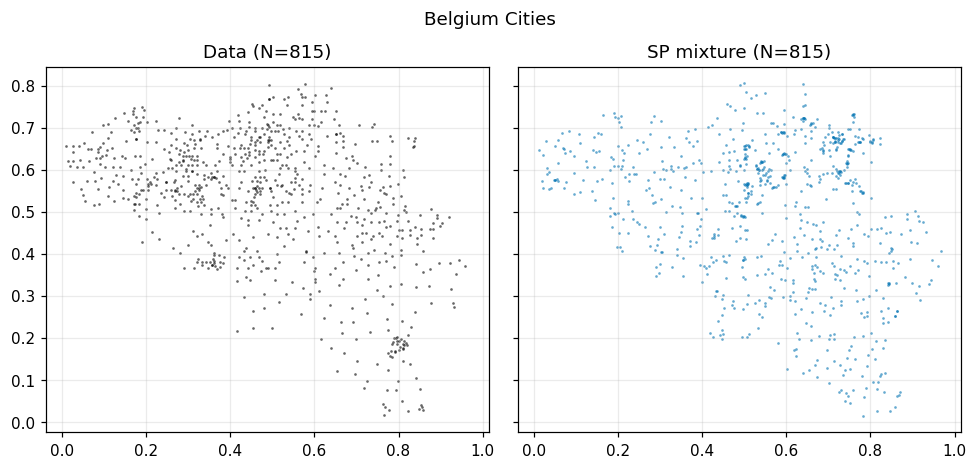

In [2]:
xy_sp, is_sp = su.build_sp_mixture(ds, ld["gdf_edge"], ld["bounds"], geom,
                                   ld["r_data"], ld["xi_data"],
                                   N_target=ld["N_real"], seed=su.SEED,
                                   verbose=True, return_labels=True)
print(f"Final mixture: {is_sp.sum()} SP nodes ({100*is_sp.sum()/len(is_sp):.0f}%) "
      f"+ {(~is_sp).sum()} background nodes (the subsampling favours the background)")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, xy, ttl, c in [(axes[0], xy_data, "Data", C["data"]),
                       (axes[1], xy_sp, "SP mixture", C["sp"])]:
    ax.scatter(*xy.T, s=3, c=c, alpha=0.6, lw=0)
    ax.set_title(f"{ttl} (N={len(xy)})"); ax.set_aspect("equal")
fig.suptitle(DATASET_NAME); fig.tight_layout(); plt.show()

## 2. Local density

- **k-NN**: ρ_k(i) = k / (π d_k(i)²), with d_k(i) the distance to the k-th neighbour
  (k = 10). The estimation radius adapts to the local density.
- **Fixed radius**: number of neighbours within h, the median 10-NN distance.

The Spearman correlation between the two measures their agreement.

radius h = 0.0419 (normalised) = 11.4 km
Rank correlation between the 2 estimators: Spearman = 0.945


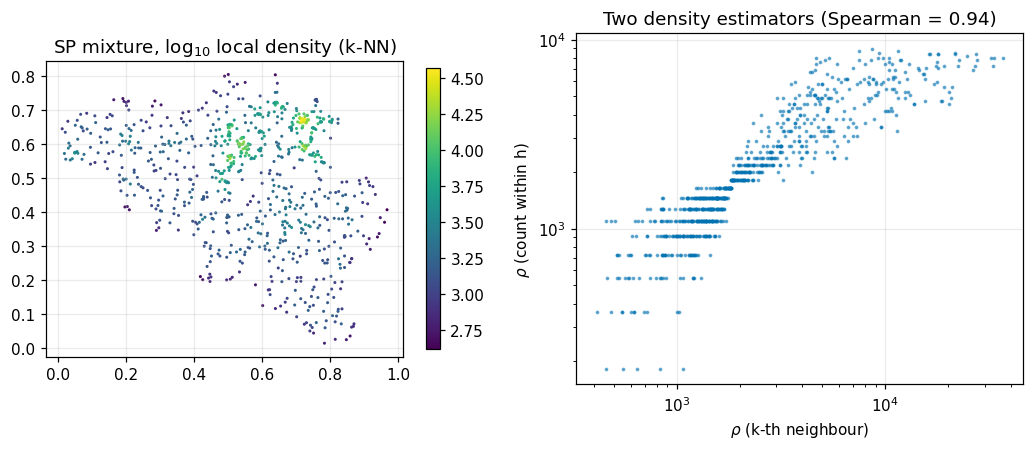

In [3]:
K_NN = 10
rho_knn = mm.local_density_knn(xy_sp, k=K_NN)
h = mm.default_radius(xy_sp, k=K_NN)          # radius = median 10-NN distance
rho_rad = mm.local_density_radius(xy_sp, h)

rs = spearmanr(rho_knn, rho_rad).statistic
print(f"radius h = {h:.4f} (normalised) = {h * ld['scale_m'] / 1e3:.1f} km")
print(f"Rank correlation between the 2 estimators: Spearman = {rs:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
sc = axes[0].scatter(*xy_sp.T, s=4, c=np.log10(rho_knn), cmap="viridis", lw=0)
axes[0].set_aspect("equal")
axes[0].set_title("SP mixture, log$_{10}$ local density (k-NN)")
fig.colorbar(sc, ax=axes[0], shrink=0.8)
axes[1].loglog(rho_knn, np.maximum(rho_rad, rho_rad[rho_rad > 0].min()),
               ".", ms=3, alpha=0.5, c=C["sp"])
axes[1].set_xlabel("$\\rho$ (k-th neighbour)")
axes[1].set_ylabel("$\\rho$ (count within h)")
axes[1].set_title(f"Two density estimators (Spearman = {rs:.2f})")
fig.tight_layout(); plt.show()

## 3. From density to population

- **(a) Power law**: population ∝ ρ^β, normalised to the real total. β is chosen so that
  the Zipf exponent of the model matches the data.
- **(b) Rank matching**: the real populations, sorted in decreasing order, are given to
  the nodes by decreasing density. The distribution is exactly the one of the data, so
  only the placement is tested.

The figure shows the three rank-size curves (data, a, b).

Zipf exponent of the data: 1.23
beta* = 1.50  ->  Zipf SP (power law): 1.32
Zipf SP (rank matching): 1.23 (= data by construction)


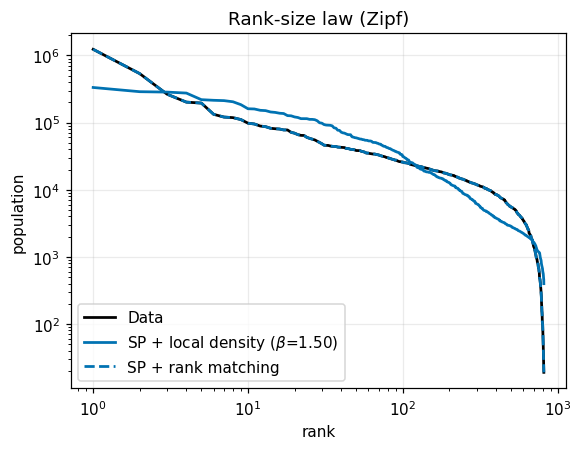

In [4]:
zipf_data = su.fit_zipf_exponent(pop_data)
beta_star, zipf_beta = mm.calibrate_beta_on_zipf(rho_knn, zipf_data, pop_data.sum())
pop_sp = mm.pop_powerlaw(rho_knn, beta_star, pop_data.sum())      # variant (a)
pop_sp_rk = mm.pop_rank_matching(rho_knn, pop_data)               # variant (b)
print(f"Zipf exponent of the data: {zipf_data:.2f}")
print(f"beta* = {beta_star:.2f}  ->  Zipf SP (power law): {zipf_beta:.2f}")
print(f"Zipf SP (rank matching): {su.fit_zipf_exponent(pop_sp_rk):.2f} (= data by construction)")

def ranksize(p):
    p = np.sort(np.asarray(p))[::-1]
    return np.arange(1, len(p) + 1), p

fig, ax = plt.subplots(figsize=(5.4, 4.2))
for p, lbl, c, ls in [(pop_data, "Data", C["data"], "-"),
                      (pop_sp, f"SP + local density ($\\beta$={beta_star:.2f})", C["sp"], "-"),
                      (pop_sp_rk, "SP + rank matching", C["sp"], "--")]:
    ax.loglog(*ranksize(p), ls, c=c, lw=1.8, label=lbl)
ax.set_xlabel("rank"); ax.set_ylabel("population")
ax.set_title("Rank-size law (Zipf)"); ax.legend()
fig.tight_layout(); plt.show()

### (c) Split by origin, SP or background

The |SP| largest populations go to the fractal nodes and the others to the background,
at random within each group (10 draws). This tests whether being a fractal node is
enough to create the coupling. Only about 23 % of the final nodes come from the fractal
on Belgium.

In [5]:
pop_sp_c = mm.pop_split_sp_background(is_sp, pop_data, seed=0)   # variant (c)
print(f"Zipf (c): {su.fit_zipf_exponent(pop_sp_c):.2f} (= data by construction)")
print(f"the {is_sp.sum()} largest populations are on the SP nodes, "
      f"the others ({(~is_sp).sum()}) on the background")

Zipf (c): 1.23 (= data by construction)
the 190 largest populations are on the SP nodes, the others (625) on the background


## 4. Coupling between population and position

- **Δγ = γ_hi − γ_lo**: 2PCF exponent of the 20 % most populated nodes minus the one of
  the others. Δγ > 0 means that large populations are more clustered.
- **k_mm(r)** (Stoyan): mean product of the populations of pairs at distance r, divided
  by ⟨population⟩². k_mm > 1 means that nearby nodes are jointly large.
- **Null**: same positions, shuffled populations (expected Δγ ≈ 0, k_mm ≈ 1).

Δγ only depends on the ranking of the nodes. Variants (a) and (b) rank the nodes in the
same way, so they give the same Δγ by construction. k_mm uses the values and separates
them.

Data                             gamma_hi=0.774  gamma_lo=0.709  dGamma=+0.065
SP + local density (a)           gamma_hi=0.705  gamma_lo=0.552  dGamma=+0.153
SP + rank matching (b)           gamma_hi=0.705  gamma_lo=0.552  dGamma=+0.153
SP + shuffled marks (null)       gamma_hi=0.944  gamma_lo=1.074  dGamma=-0.130
SP + SP/background split (c)     dGamma=-0.190 +- 0.375  (10 draws, unstable: 2PCF fit on about 20% of fractal nodes)

Spearman(a, b) = 1.0000  -> identical ranking, so dGamma(a) = dGamma(b) by construction


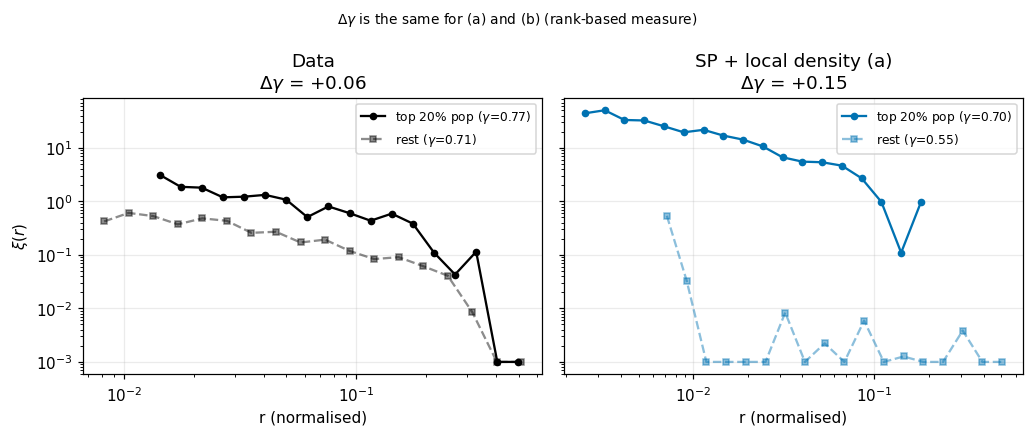

In [6]:
rng = np.random.default_rng(0)

# Both variants are propagated to every measure. On Delta gamma they give the SAME
# result (rank-based measure, see above). It is printed as a check, and only two
# panels are plotted.
res = {}
res["Data"] = mm.delta_gamma(xy_data, pop_data, geom)
res["SP + local density (a)"] = mm.delta_gamma(xy_sp, pop_sp, geom)
res["SP + rank matching (b)"] = mm.delta_gamma(xy_sp, pop_sp_rk, geom)
res["SP + shuffled marks (null)"] = mm.delta_gamma(xy_sp, rng.permutation(pop_sp), geom)

# (c) is random inside each group: mean and standard deviation over 10 draws
dg_c_draws = [mm.delta_gamma(xy_sp, mm.pop_split_sp_background(is_sp, pop_data, seed=s_), geom)[1]
              for s_ in range(10)]
dg_c, dg_c_std = float(np.nanmean(dg_c_draws)), float(np.nanstd(dg_c_draws))

for k, (r, dg) in res.items():
    print(f"{k:32s} gamma_hi={r['gamma_hi']:.3f}  gamma_lo={r['gamma_lo']:.3f}  "
          f"dGamma={dg:+.3f}")
print(f"{'SP + SP/background split (c)':32s} dGamma={dg_c:+.3f} +- {dg_c_std:.3f}  "
      f"(10 draws, unstable: 2PCF fit on about 20% of fractal nodes)")
print(f"\nSpearman(a, b) = {spearmanr(pop_sp, pop_sp_rk).statistic:.4f}  "
      f"-> identical ranking, so dGamma(a) = dGamma(b) by construction")

panels = [("Data", "data"), ("SP + local density (a)", "sp")]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), sharey=True)
for ax, (key, ckey) in zip(axes, panels):
    r, dg = res[key]
    ax.loglog(r["r_hi"], np.clip(r["xi_hi"], 1e-3, None), "o-", ms=4, c=C[ckey],
              label=f"top 20% pop ($\\gamma$={r['gamma_hi']:.2f})")
    ax.loglog(r["r_lo"], np.clip(r["xi_lo"], 1e-3, None), "s--", ms=4, c=C[ckey],
              alpha=0.45, label=f"rest ($\\gamma$={r['gamma_lo']:.2f})")
    ax.set_title(f"{key}\n$\\Delta\\gamma$ = {dg:+.2f}")
    ax.set_xlabel("r (normalised)"); ax.legend(fontsize=8)
axes[0].set_ylabel("$\\xi(r)$")
fig.suptitle("$\\Delta\\gamma$ is the same for (a) and (b) (rank-based measure)", fontsize=9)
fig.tight_layout(); plt.show()

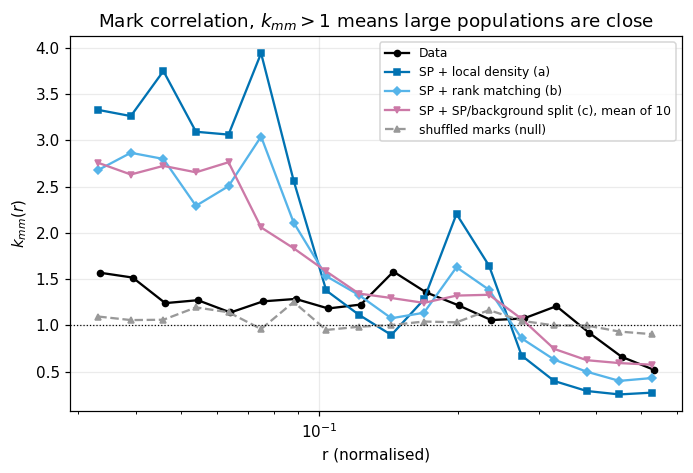

In [7]:
r_d, k_d = su.mark_correlation_function(xy_data, pop_data)
r_a, k_a = su.mark_correlation_function(xy_sp, pop_sp)
r_b, k_b = su.mark_correlation_function(xy_sp, pop_sp_rk)
r_n, k_n = su.mark_correlation_function(xy_sp, rng.permutation(pop_sp))
# (c): mean k_mm over 10 draws inside the groups
k_c_list = []
for s_ in range(10):
    r_c, k_c_ = su.mark_correlation_function(
        xy_sp, mm.pop_split_sp_background(is_sp, pop_data, seed=s_))
    k_c_list.append(k_c_)
k_c = np.nanmean(k_c_list, axis=0)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.semilogx(r_d, k_d, "o-", ms=4, c=C["data"], label="Data")
ax.semilogx(r_a, k_a, "s-", ms=4, c=C["sp"], label="SP + local density (a)")
ax.semilogx(r_b, k_b, "D-", ms=4, c=C["rk"], label="SP + rank matching (b)")
ax.semilogx(r_c, k_c, "v-", ms=4, c=C["split"], label="SP + SP/background split (c), mean of 10")
ax.semilogx(r_n, k_n, "^--", ms=4, c=C["null"], label="shuffled marks (null)")
ax.axhline(1, c="k", lw=0.8, ls=":")
ax.set_xlabel("r (normalised)"); ax.set_ylabel("$k_{mm}(r)$")
ax.set_title("Mark correlation, $k_{mm}>1$ means large populations are close")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 5. "Level" option

Population ∝ η^(−slope × level) on the SP tree (`build_sp_with_population`), with the
slope fitted on the Zipf exponent. It only applies to the fractal, without background.

In [8]:
slope_star, zipf_lvl = su.calibrate_sp_slope(ds, ld["gdf_edge"], zipf_data, seed=su.SEED)
spp = su.build_sp_with_population(ds, ld["gdf_edge"], slope=slope_star, seed=su.SEED)
res_lvl, dg_lvl = mm.delta_gamma(spp["xy_norm"], spp["pop"], geom)
print(f"Level option: slope*={slope_star:.2f} (Zipf={zipf_lvl:.2f}), "
      f"N={len(spp['pop'])} nodes (tree only, no background)")
print(f"dGamma (level) = {dg_lvl:+.3f}")

Level option: slope*=1.23 (Zipf=1.16), N=1534 nodes (tree only, no background)
dGamma (level) = -0.063


                                               variant  zipf  delta_gamma
                                                  Data 1.228        0.065
                        SP mixture + local density (a) 1.316        0.153
                        SP mixture + rank matching (b) 1.228        0.153
SP mixture + SP/background split (c), mean of 10 draws 1.228       -0.190
                    SP mixture + shuffled marks (null) 1.316       -0.130
                                SP tree + level option 1.161       -0.063
-> /home/emery/kDrive/Pro/Code/FakeWorld/fake_world_emile-paper-2026/out/01_metadata_generative_summary.csv


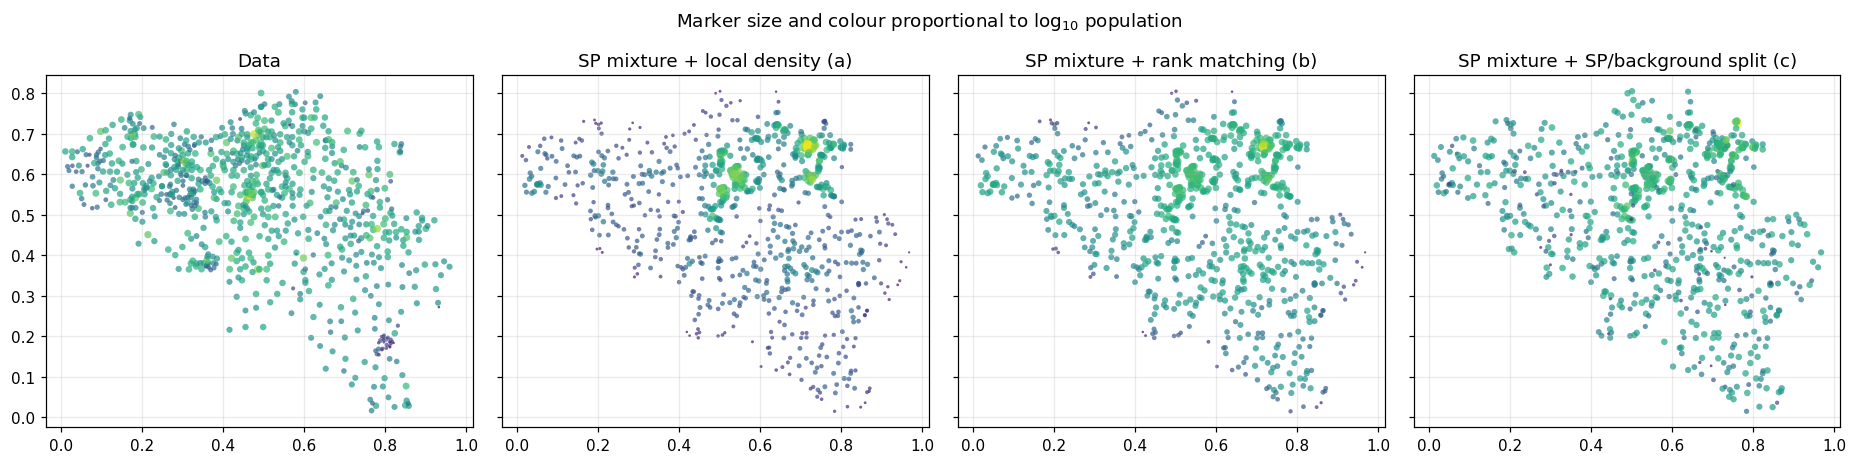

In [9]:
import pandas as pd

_, dg_data = res["Data"]
_, dg_a = res["SP + local density (a)"]
_, dg_b = res["SP + rank matching (b)"]
_, dg_null = res["SP + shuffled marks (null)"]
zipf_rk = su.fit_zipf_exponent(pop_sp_rk)
summary = pd.DataFrame([
    dict(variant="Data", zipf=round(zipf_data, 3), delta_gamma=round(dg_data, 3)),
    dict(variant="SP mixture + local density (a)", zipf=round(zipf_beta, 3),
         delta_gamma=round(dg_a, 3)),
    dict(variant="SP mixture + rank matching (b)", zipf=round(zipf_rk, 3),
         delta_gamma=round(dg_b, 3)),
    dict(variant="SP mixture + SP/background split (c), mean of 10 draws",
         zipf=round(su.fit_zipf_exponent(pop_sp_c), 3), delta_gamma=round(dg_c, 3)),
    dict(variant="SP mixture + shuffled marks (null)", zipf=round(zipf_beta, 3),
         delta_gamma=round(dg_null, 3)),
    dict(variant="SP tree + level option", zipf=round(zipf_lvl, 3),
         delta_gamma=round(dg_lvl, 3)),
])
out_csv = ROOT / "out" / "01_metadata_generative_summary.csv"
summary.to_csv(out_csv, index=False)
print(summary.to_string(index=False))
print("->", out_csv)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
for ax, xy, p, ttl in [(axes[0], xy_data, pop_data, "Data"),
                       (axes[1], xy_sp, pop_sp, "SP mixture + local density (a)"),
                       (axes[2], xy_sp, pop_sp_rk, "SP mixture + rank matching (b)"),
                       (axes[3], xy_sp, pop_sp_c, "SP mixture + SP/background split (c)")]:
    lp = np.log10(p)
    s = 2 + 28 * (lp - lp.min()) / (lp.max() - lp.min())
    ax.scatter(*xy.T, s=s, c=lp, cmap="viridis", alpha=0.7, lw=0)
    ax.set_aspect("equal"); ax.set_title(ttl)
fig.suptitle("Marker size and colour proportional to log$_{10}$ population")
fig.tight_layout(); plt.show()

## Results (Belgium)

| variant | Zipf | Δγ |
|---|---|---|
| data | 1.23 | +0.07 |
| (a) local density, ρ^β | 1.32 | +0.15 |
| (b) rank matching | 1.23 | +0.15 |
| (c) SP / background split | 1.23 | −0.19 ± 0.38 |
| null, shuffled marks | 1.32 | −0.13 |
| level option (tree only) | 1.16 | −0.06 |

- The local density, (a) or (b), gives a positive coupling, on the side of the data and
  away from the null. It is twice the one of the data.
- The split by origin (c) and the level option do not give the coupling. The coupling
  comes from the node-by-node link between density and population.
- Only Belgium carries real city populations in the distributed data.